# 01 — Exploratory Data Analysis: FRA Atlas scheme-suitability dataset

**Dataset:** `ml/data/labeled_dataset.csv`: 1,540 synthetic plots, 220 in each of 7 districts.

**Read this first: what this data is and isn't**
- The plots are **synthetic**. Their coordinates were sampled inside real district boundaries; they are not real FRA claims.
- Soil and elevation are **real API readings** (ISRIC SoilGrids, open-elevation). About 25–29% of those cells were **imputed** with district means, mostly in Kandhamal (~83%) and Koraput (~65%).
- `groundwater_stress_pct` and `rainfall_mm_avg` are **district constants**: 7 values each, one per district.
- The six `*_score` columns are **rule-derived labels**: `backend/services/scheme_rules.py` plus Gaussian noise. They are not real scheme allocations or eligibility decisions. Whatever this notebook finds describes how those rules behave on this data, not real-world scheme outcomes.

**How to read this notebook:** the **Findings** come first, each with one chart as evidence and one line on what it means for the product. The detailed EDA (structure, distributions, cleaning, encoding, scaling, transforms, engineered features, PCA) follows, and the notebook ends with a **Decisions log** that Stage 2 (modelling) will follow.

## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor, BallTree
from sklearn.model_selection import KFold, GroupKFold, GroupShuffleSplit, LeaveOneGroupOut, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (8, 4.5)})

# Locate the repo root whether this runs from ml/notebooks/ or the repo root.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml" / "data" / "labeled_dataset.csv").exists())
sys.path.insert(0, str(ROOT / "fra-atlas"))
from backend.services import scheme_rules as sr   # the rules that generated the labels

df = pd.read_csv(ROOT / "ml" / "data" / "labeled_dataset.csv")

TARGETS = ["pm_kisan_score", "mgnrega_score", "jjm_score", "pmfby_score", "pmksy_score", "soil_health_card_score"]
SHORT = {t: t.replace("_score", "") for t in TARGETS}
PRIMARY = ["mgnrega_score", "pmksy_score", "soil_health_card_score"]
# R^2 ceilings from check_labels.py (signal variance / (signal + noise variance))
CEILING = {"pm_kisan_score": 0.975, "soil_health_card_score": 0.922, "pmksy_score": 0.917,
           "jjm_score": 0.846, "pmfby_score": 0.627, "mgnrega_score": 0.583}
NUMERIC = ["land_area_ha", "soil_ph", "soil_organic_carbon", "soil_clay_pct", "elevation_m",
           "groundwater_stress_pct", "rainfall_mm_avg", "lat", "lon"]
IMPUTED_FLAGS = [c for c in df.columns if c.endswith("_imputed")]
# Which raw features each rule actually reads (from scheme_rules.py)
RULE_INPUTS = {
    "pm_kisan_score": {"claim_type"},
    "mgnrega_score": {"groundwater_stress_pct", "soil_ph", "soil_organic_carbon", "land_area_ha", "claim_type"},
    "jjm_score": {"rainfall_mm_avg", "groundwater_stress_pct"},
    "pmfby_score": {"rainfall_mm_avg"},
    "pmksy_score": {"groundwater_stress_pct", "rainfall_mm_avg", "land_area_ha", "claim_type", "soil_ph", "soil_organic_carbon"},
    "soil_health_card_score": {"soil_ph", "soil_organic_carbon"},
}
DISTRICT_ORDER = sorted(df.district.unique())

# Model-ready matrix used by several findings (claim_type one-hot; IFR/CFR, CR is the reference level)
df["is_ifr"] = (df.claim_type == "IFR").astype(int)
df["is_cfr"] = (df.claim_type == "CFR").astype(int)
FEATS = ["land_area_ha", "is_ifr", "is_cfr", "soil_ph", "soil_organic_carbon", "soil_clay_pct",
         "elevation_m", "groundwater_stress_pct", "rainfall_mm_avg", "lat", "lon"]
FEAT_TO_RAW = {"is_ifr": "claim_type", "is_cfr": "claim_type"}

def eta2(y, groups):
    # Share of variance in y explained by group means alone (R^2 of 'predict the group mean').
    gm = y.groupby(groups).transform("mean")
    return 1 - ((y - gm) ** 2).sum() / ((y - y.mean()) ** 2).sum()

def rf():
    return RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)

print(df.shape)

(1540, 26)


---
# Findings


Each finding has its evidence chart directly below this list (F1–F10). All of them describe **the rules in `scheme_rules.py` acting on this synthetic dataset**, not real scheme outcomes.

**F1. Three of the six scores are district lookups.** District alone explains **85% of `jjm`, 87% of `pmksy` and 62% of `pmfby`**, which is essentially all of their explainable variance (ceilings 0.846 / 0.917 / 0.627). Only three labels carry plot-level signal: `pm_kisan` (0.97, from claim type), `mgnrega` (0.46 left inside a district) and `soil_health_card` (0.45).
→ *Product:* for jjm, pmfby and pmksy the DSS is really giving a **district-level** indicator. Present it that way, not as an assessment of the individual plot.

**F2. Feature importance credits proxies, not causes.** The forest finds the true drivers where they vary by plot: `is_ifr` for pm_kisan, organic carbon + pH for soil_health_card, and `is_ifr` + OC + land area for mgnrega. But `pmfby`'s rule reads **only rainfall**, and the model credits **longitude (1.12) instead of rainfall (0.006)**. `lat` gets 0.11 for mgnrega even though no rule uses it. Any district-constant column can stand in for any other.
→ *Product:* if lat/lon stay in the model, the DSS panel's "top contributing inputs" would tell an officer that *longitude* drives crop-insurance suitability. Drop lat/lon so the explanations name the real inputs.

**F3. The atlas view: dry vs wet districts split the schemes.** The largest district spreads are `jjm` 43 points (Shivpuri 82 vs West Tripura 39), `pmksy` 33 (Shivpuri 77 vs Koraput 44) and `soil_health_card` 32 (West Tripura 62 vs Warangal 31). Dry districts (Shivpuri, Warangal, Chhindwara, Adilabad) rank high for jjm/pmksy, wet ones (West Tripura, Kandhamal, Koraput) for pmfby. `mgnrega` (8 points) and `pm_kisan` (7) barely differ between districts.
→ *Product:* the district × scheme heatmap is the most useful planning view the data supports. It rests on 7 reference climate values, and only Chhindwara's rainfall is verified.

**F4. Imputed soil rows carry no soil signal.** 459 rows (30%) have imputed soil; each district's imputed rows share **one** pH/OC value. In Kandhamal + Koraput, `soil_health_card` varies with std **3.8 on imputed rows vs 9.1 on real rows**. 3.8 is about the label noise (SD 4), so those labels are one rule value plus noise.
→ *Product:* soil-based DSS output for Kandhamal and Koraput is a district average and must carry an "estimated" flag. Stage 2 reports errors separately for imputed and real rows.

**F5. `lat`, `lon`, `elevation_m` and `soil_clay_pct` are inert, and so is `soil_ph` *within* a district.** Within-district |r| with every label is ≤ 0.11 for those four. The surprise is `soil_ph` (|r| ≤ 0.03): pH barely varies inside a district (std 0.09–0.25), and districts are either almost all acidic (Kandhamal 100%, Koraput 98%, West Tripura 100%) or almost none (≤ 11%). Plot-level soil_health_card variation comes from **organic carbon** (r = −0.47).
→ *Product:* in practice the pH part of the soil score is a district flag. Organic carbon is the soil input that differs between neighbouring plots.

**F6. The constructed organic-carbon cutoffs matter more than the official pH cutoff.** Only 2.8% of plots sit within ±0.1 of pH 6.5. Shifting the pH cutoff by ±0.25 changes the soil score of **2–4%** of plots, while shifting the *constructed* OC cutoff by ±0.25 percentage points changes **10–15%** (up to 31% when combined with a pH move to 6.0).
→ *Product:* the OC bands (1.5% / 2.0%, taken from this data's thirds) need a sourced justification in the methodology note before soil scores are shown as anything more than illustrative.

**F7. Random splits barely leak here; new districts are the real risk.** 36% of plots have a neighbour within 1 km, yet random-vs-group R² differs by **≤ 0.006** for the forest (max 0.019, KNN on soil_health_card), because the label noise is independent for each plot. Leave-one-district-out is where it breaks: **jjm 0.83 → 0.22, pmfby 0.58 → 0.30, pmksy 0.90 → 0.73, soil_health_card 0.90 → 0.76**.
→ *Product:* the model must not score plots outside the 7 training districts. The DSS should refuse, or loudly flag, an out-of-district claim.

**F8. Six labels, about four independent signals.** Four principal components of the standardized labels explain 92% of their variance. The climate cluster moves together: jjm~pmksy +0.80, jjm~pmfby −0.69, pmfby~pmksy −0.61.
→ *Product:* show the six scores grouped (a water/climate cluster vs claim-type vs soil), so officers don't read six agreeing scores as six independent pieces of evidence.

**F9. `pm_kisan` is a claim-type echo.** `pm_kisan_score > 50` matches `claim_type == "IFR"` on **100%** of plots (840/840, no exceptions).
→ *Product:* a model adds nothing for PM-KISAN; the DSS can state the rule directly ("IFR title holder"). This makes it the perfect sanity check for the Stage 2 classification pipeline.

**F10. The entire climate signal is 7 numbers.** `groundwater_stress_pct` and `rainfall_mm_avg` each take exactly one value per district, all inside the CGWB "safe" band (30–65%).
→ *Product:* nothing about how climate affects suitability can be learned beyond these 7 points. Adding a district means sourcing its real rainfall and groundwater figures first.

### Finding 1 evidence: how much of each score is district alone?

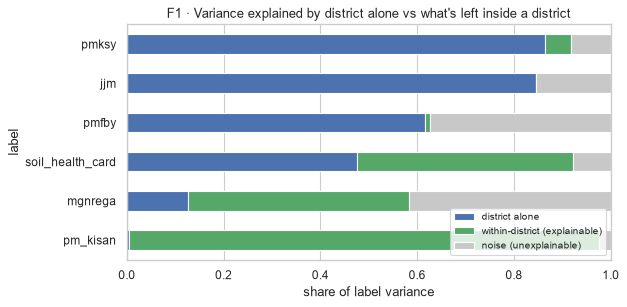

,district alone,within-district (explainable),noise (unexplainable)
label,,,
pm_kisan,0.005,0.970,0.025
mgnrega,0.126,0.457,0.417
soil_health_card,0.477,0.445,0.078
pmfby,0.617,0.010,0.373
jjm,0.846,0.000,0.154
pmksy,0.865,0.052,0.083


In [2]:
rows = []
for t in TARGETS:
    d = eta2(df[t], df.district)
    rows.append({"label": SHORT[t], "district alone": d,
                 "within-district (explainable)": max(CEILING[t] - d, 0),
                 "noise (unexplainable)": 1 - CEILING[t]})
f1 = pd.DataFrame(rows).set_index("label").sort_values("district alone")
ax = f1.plot.barh(stacked=True, color=["#4C72B0", "#55A868", "#C8C8C8"], figsize=(8, 4))
ax.set_xlabel("share of label variance"); ax.set_xlim(0, 1); ax.legend(loc="lower right", fontsize=9)
ax.set_title("F1 · Variance explained by district alone vs what's left inside a district")
plt.tight_layout(); plt.show()
f1.round(3)

### Finding 2 evidence: which features actually drive each score?
A random forest is trained on a **group split** (whole `spatial_block`s held out). Then we shuffle one feature at a time on the held-out plots and measure how much R² drops (*permutation importance*). Cells outlined in black are the features the rule in `scheme_rules.py` actually reads.

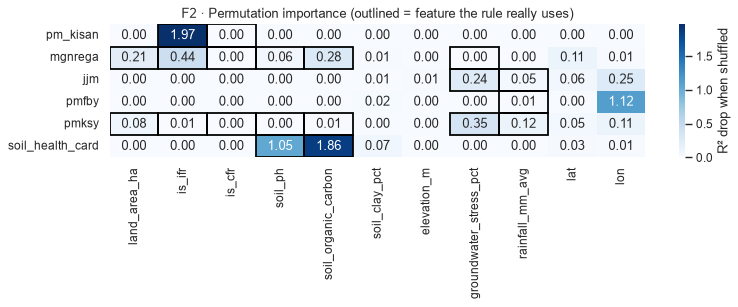

In [3]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(df, groups=df.spatial_block))
imp = {}
for t in TARGETS:
    m = rf().fit(df.loc[tr_idx, FEATS], df.loc[tr_idx, t])
    pi = permutation_importance(m, df.loc[te_idx, FEATS], df.loc[te_idx, t], n_repeats=10, random_state=SEED)
    imp[SHORT[t]] = pd.Series(pi.importances_mean, index=FEATS)
imp = pd.DataFrame(imp).T.clip(lower=0)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(imp, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "R² drop when shuffled"}, ax=ax)
for i, t in enumerate(TARGETS):
    for j, f in enumerate(FEATS):
        if FEAT_TO_RAW.get(f, f) in RULE_INPUTS[t]:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, ec="black", lw=1.6))
ax.set_title("F2 · Permutation importance (outlined = feature the rule really uses)")
plt.tight_layout(); plt.show()

### Finding 3 evidence: the atlas view (mean score per district × scheme)

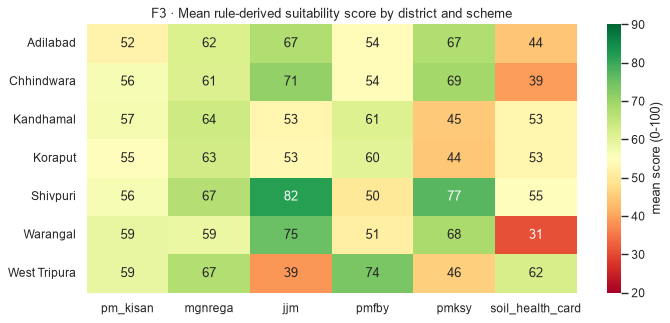

Range of district means per scheme (max - min):
jjm                 43.2
pmksy               32.8
soil_health_card    31.5
pmfby               23.9
mgnrega              8.3
pm_kisan             6.9


In [4]:
atlas = df.groupby("district")[TARGETS].mean().rename(columns=SHORT).loc[DISTRICT_ORDER]
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.heatmap(atlas, annot=True, fmt=".0f", cmap="RdYlGn", vmin=20, vmax=90, ax=ax, cbar_kws={"label": "mean score (0-100)"})
ax.set_title("F3 · Mean rule-derived suitability score by district and scheme"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print("Range of district means per scheme (max - min):")
print((atlas.max() - atlas.min()).round(1).sort_values(ascending=False).to_string())

### Finding 4 evidence: are the imputed rows distorting anything?
An imputed row got its district's **mean** soil value, so every imputed row in a district has the **same** pH and organic carbon. That makes the soil-driven label (`soil_health_card`) almost constant across those rows: only the label noise is left.

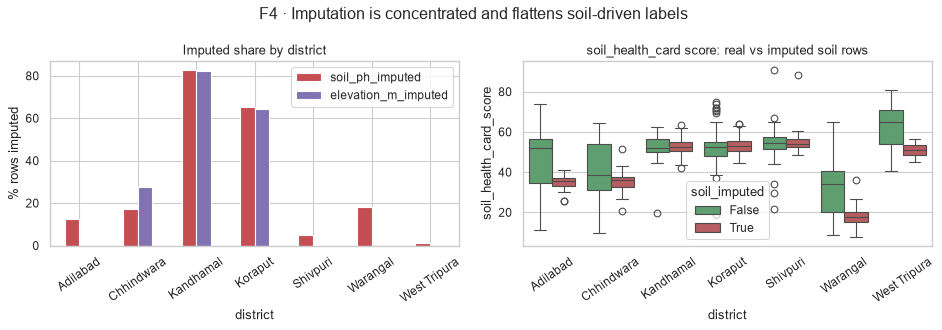

              rows  ph_distinct  shc_std
soil_imputed                            
False         1081           25    15.08
True           459           14    11.92

Kandhamal+Koraput, SHC std by imputed flag:
soil_imputed
False    9.10
True     3.82


In [5]:
df["soil_imputed"] = df.soil_ph_imputed | df.soil_organic_carbon_imputed
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
share = df.groupby("district")[["soil_ph_imputed", "elevation_m_imputed"]].mean().loc[DISTRICT_ORDER] * 100
share.plot.bar(ax=axes[0], color=["#C44E52", "#8172B2"]); axes[0].set_ylabel("% rows imputed")
axes[0].set_title("Imputed share by district"); axes[0].tick_params(axis="x", rotation=35)
sns.boxplot(data=df, x="district", y="soil_health_card_score", hue="soil_imputed", order=DISTRICT_ORDER,
            palette={False: "#55A868", True: "#C44E52"}, ax=axes[1])
axes[1].set_title("soil_health_card score: real vs imputed soil rows"); axes[1].tick_params(axis="x", rotation=35)
fig.suptitle("F4 · Imputation is concentrated and flattens soil-driven labels"); plt.tight_layout(); plt.show()

f4 = df.groupby("soil_imputed").agg(rows=("plot_id", "size"),
                                    ph_distinct=("soil_ph", "nunique"),
                                    shc_std=("soil_health_card_score", "std"))
print(f4.round(2).to_string())
# Within Kandhamal + Koraput only
kk = df[df.district.isin(["Kandhamal", "Koraput"])]
print("\nKandhamal+Koraput, SHC std by imputed flag:")
print(kk.groupby("soil_imputed").soil_health_card_score.std().round(2).to_string())

### Finding 5 evidence: which features are inert?
Comparing across districts is misleading here: any feature that differs between districts will *look* related to a district-driven label. So we first subtract each district's mean from both the feature and the label (**within-district** correlation), then correlate.

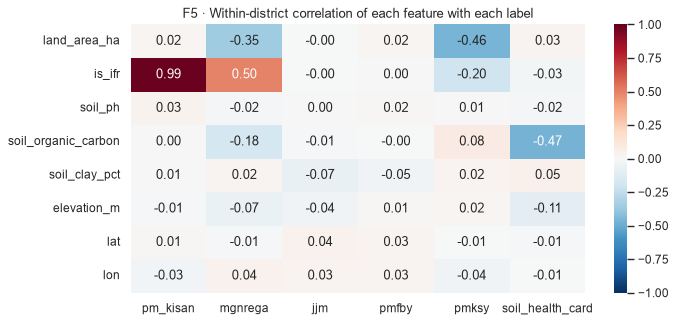

max |within-district r| per feature:
soil_ph                0.03
lon                    0.04
lat                    0.04
soil_clay_pct          0.07
elevation_m            0.11
land_area_ha           0.46
soil_organic_carbon    0.47
is_ifr                 0.99


In [6]:
def within(s):
    return s - s.groupby(df.district).transform("mean")

feat_cols = ["land_area_ha", "is_ifr", "soil_ph", "soil_organic_carbon", "soil_clay_pct", "elevation_m", "lat", "lon"]
wc = pd.DataFrame({SHORT[t]: [np.corrcoef(within(df[f]), within(df[t]))[0, 1] for f in feat_cols] for t in TARGETS},
                  index=feat_cols)
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.heatmap(wc, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("F5 · Within-district correlation of each feature with each label")
plt.tight_layout(); plt.show()
print("max |within-district r| per feature:")
print(wc.abs().max(axis=1).round(2).sort_values().to_string())

### Finding 6 evidence: how sensitive are the scores to the pH / organic-carbon cutoffs?
We re-run the **noiseless** soil-health-card rule from `scheme_rules.py` with different cutoffs and count how many plots get a different score. The official Soil Health Card pH band starts at 6.5. The organic-carbon cutoffs (1.5% / 2.0%) were *constructed* from this data's own thirds, not taken from the official card.

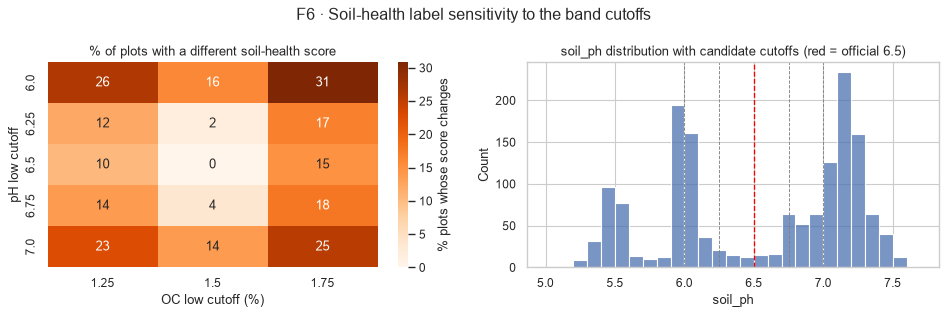

Plots within +/-0.1 of the pH 6.5 cutoff: 2.8%


In [7]:
def shc_noiseless(ph_low, oc_low, oc_high=sr.OC_HIGH_PCT):
    saved = (sr.PH_LOW, sr.OC_LOW_PCT, sr.OC_HIGH_PCT)
    sr.PH_LOW, sr.OC_LOW_PCT, sr.OC_HIGH_PCT = ph_low, oc_low, oc_high
    try:
        return np.array([0.5 * sr._ph_need(r.soil_ph) + 0.5 * sr._oc_need(r.soil_organic_carbon / 10)
                         for r in df.itertuples()])
    finally:
        sr.PH_LOW, sr.OC_LOW_PCT, sr.OC_HIGH_PCT = saved

base = shc_noiseless(sr.PH_LOW, sr.OC_LOW_PCT)
ph_grid = [6.0, 6.25, 6.5, 6.75, 7.0]
oc_grid = [1.25, 1.5, 1.75]
changed = pd.DataFrame({oc: [(shc_noiseless(ph, oc) != base).mean() * 100 for ph in ph_grid] for oc in oc_grid},
                       index=ph_grid)
changed.index.name = "pH low cutoff"; changed.columns.name = "OC low cutoff (%)"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(changed, annot=True, fmt=".0f", cmap="Oranges", ax=axes[0], cbar_kws={"label": "% plots whose score changes"})
axes[0].set_title("% of plots with a different soil-health score")
sns.histplot(df.soil_ph, bins=np.arange(5.0, 7.8, 0.1), ax=axes[1], color="#4C72B0")
for c in ph_grid:
    axes[1].axvline(c, color="red" if c == 6.5 else "grey", ls="--", lw=1.2 if c == 6.5 else 0.8)
axes[1].set_title("soil_ph distribution with candidate cutoffs (red = official 6.5)")
fig.suptitle("F6 · Soil-health label sensitivity to the band cutoffs"); plt.tight_layout(); plt.show()
print(f"Plots within +/-0.1 of the pH 6.5 cutoff: {(df.soil_ph.sub(6.5).abs() <= 0.1).mean():.1%}")

### Finding 7 evidence: random split vs group split vs leave-one-district-out
Same random forest, three ways of testing it:
- **random 5-fold**: neighbouring plots can sit on both sides of the split (the classic leak).
- **GroupKFold on `spatial_block`**: whole ~33 km blocks are held out together.
- **leave-one-district-out (LODO)**: a whole district is held out. This is the "brand-new district" test.

All R² values are computed on pooled out-of-fold predictions (per-fold R² is meaningless inside one district, where some labels barely vary).

Plots with another plot within 1 km: 35.9%  (median nearest neighbour 2.17 km)


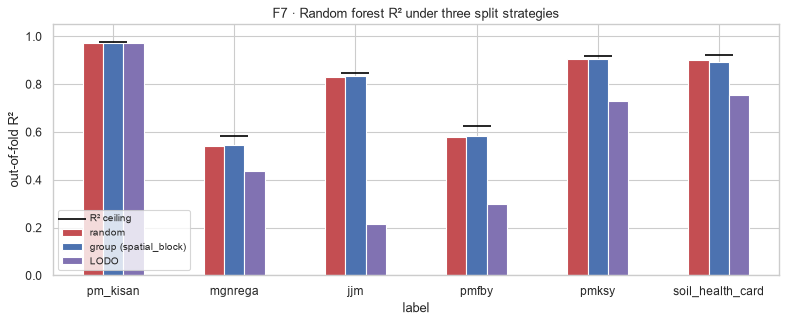

,label,model,random,group (spatial_block),LODO,leak gap (random - group)
0,pm_kisan,RF,0.974,0.974,0.974,-0.000
1,pm_kisan,KNN,0.970,0.969,0.957,0.001
2,mgnrega,RF,0.541,0.545,0.437,-0.004
3,mgnrega,KNN,0.410,0.411,0.335,-0.002
4,jjm,RF,0.831,0.833,0.216,-0.002
5,jjm,KNN,0.818,0.815,0.534,0.004
6,pmfby,RF,0.578,0.583,0.300,-0.005
7,pmfby,KNN,0.537,0.543,0.251,-0.006
8,pmksy,RF,0.905,0.904,0.731,0.000
9,pmksy,KNN,0.888,0.883,0.793,0.005


In [8]:
def oof_r2(model, t, cv, groups=None):
    pred = cross_val_predict(model, df[FEATS], df[t], cv=cv, groups=groups)
    return r2_score(df[t], pred)

nn_tree = BallTree(np.radians(df[["lat", "lon"]].values), metric="haversine")
dist, _ = nn_tree.query(np.radians(df[["lat", "lon"]].values), k=2)
nn_km = dist[:, 1] * 6371
print(f"Plots with another plot within 1 km: {(nn_km < 1).mean():.1%}  (median nearest neighbour {np.median(nn_km):.2f} km)")

res = []
for t in TARGETS:
    for name, mk in [("RF", rf), ("KNN", lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(5)))]:
        res.append({"label": SHORT[t], "model": name,
                    "random": oof_r2(mk(), t, KFold(5, shuffle=True, random_state=SEED)),
                    "group (spatial_block)": oof_r2(mk(), t, GroupKFold(5), df.spatial_block),
                    "LODO": oof_r2(mk(), t, LeaveOneGroupOut(), df.district)})
f7 = pd.DataFrame(res)
f7["leak gap (random - group)"] = f7["random"] - f7["group (spatial_block)"]

plot = f7[f7.model == "RF"].set_index("label")[["random", "group (spatial_block)", "LODO"]]
ax = plot.plot.bar(figsize=(10, 4.2), color=["#C44E52", "#4C72B0", "#8172B2"])
ax.scatter(range(len(plot)), [CEILING[t + "_score"] for t in plot.index], marker="_", s=600, color="black", zorder=3, label="R² ceiling")
ax.axhline(0, color="black", lw=0.8); ax.set_ylim(min(0, plot.values.min() - 0.05), 1.05); ax.set_ylabel("out-of-fold R²")
ax.set_title("F7 · Random forest R² under three split strategies")
ax.legend(fontsize=9, loc="lower left"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
f7.round(3)

### Finding 8 evidence: how correlated are the six labels?

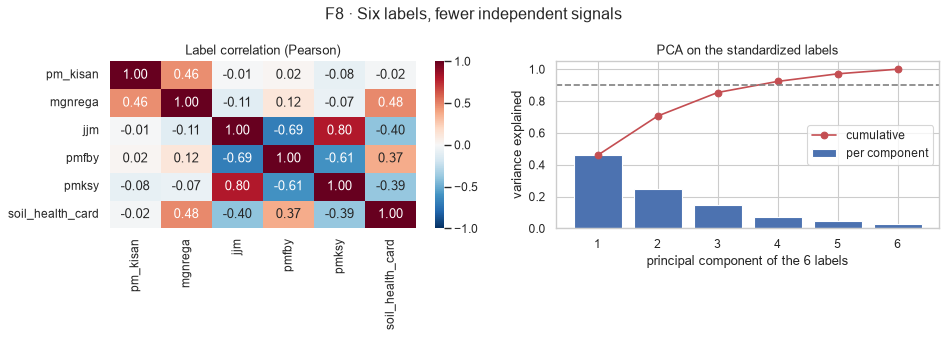

cumulative variance: [0.459 0.706 0.854 0.923 0.971 1.   ]
components for 90%: 4


In [9]:
lab = df[TARGETS].rename(columns=SHORT)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
sns.heatmap(lab.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Label correlation (Pearson)")
pca_lab = PCA().fit(StandardScaler().fit_transform(lab))
cum = np.cumsum(pca_lab.explained_variance_ratio_)
axes[1].bar(range(1, 7), pca_lab.explained_variance_ratio_, color="#4C72B0", label="per component")
axes[1].plot(range(1, 7), cum, "o-", color="#C44E52", label="cumulative")
axes[1].axhline(0.9, ls="--", color="grey"); axes[1].set_xlabel("principal component of the 6 labels")
axes[1].set_ylabel("variance explained"); axes[1].legend(); axes[1].set_title("PCA on the standardized labels")
fig.suptitle("F8 · Six labels, fewer independent signals"); plt.tight_layout(); plt.show()
print("cumulative variance:", np.round(cum, 3))
print("components for 90%:", int(np.argmax(cum >= 0.9) + 1))

### Finding 9 evidence: pm_kisan is a claim-type lookup (classification sanity check)

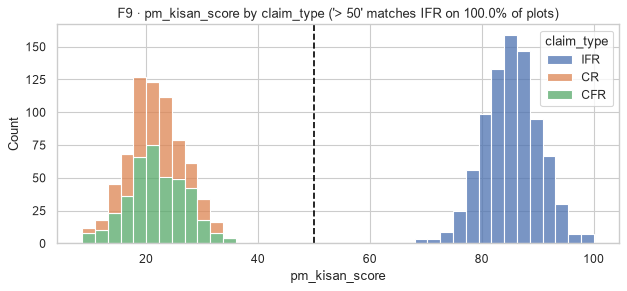

pm_kisan_class    0    1   All
claim_type                    
CFR             390    0   390
CR              310    0   310
IFR               0  840   840
All             700  840  1540


In [10]:
df["pm_kisan_class"] = (df.pm_kisan_score > 50).astype(int)
agree = (df.pm_kisan_class == df.is_ifr).mean()
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(data=df, x="pm_kisan_score", hue="claim_type", bins=40, multiple="stack", ax=ax)
ax.axvline(50, color="black", ls="--"); ax.set_title(f"F9 · pm_kisan_score by claim_type ('> 50' matches IFR on {agree:.1%} of plots)")
plt.tight_layout(); plt.show()
print(pd.crosstab(df.claim_type, df.pm_kisan_class, margins=True))

### Finding 10 evidence: groundwater and rainfall are 7-value district stand-ins

             groundwater_stress_pct       rainfall_mm_avg        
                            nunique first         nunique   first
district                                                         
Adilabad                          1  45.0               1  1100.0
Chhindwara                        1  58.0               1  1150.0
Kandhamal                         1  32.0               1  1450.0
Koraput                           1  30.0               1  1400.0
Shivpuri                          1  65.0               1   850.0
Warangal                          1  55.0               1   950.0
West Tripura                      1  40.0               1  2100.0


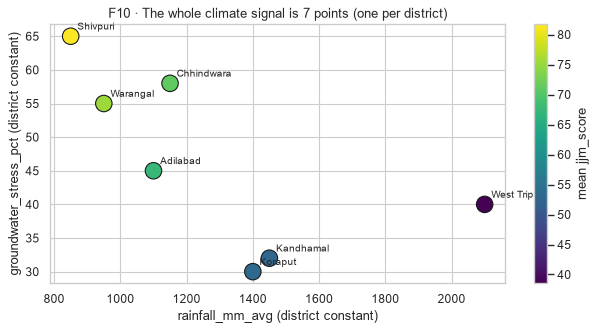

In [11]:
dc = df.groupby("district")[["groundwater_stress_pct", "rainfall_mm_avg"]].agg(["nunique", "first"])
print(dc.to_string())
pts = df.groupby("district")[["groundwater_stress_pct", "rainfall_mm_avg", "jjm_score", "pmfby_score"]].mean()
fig, ax = plt.subplots(figsize=(8, 4.3))
sc = ax.scatter(pts.rainfall_mm_avg, pts.groundwater_stress_pct, c=pts.jjm_score, s=220, cmap="viridis", edgecolor="k")
for d, r in pts.iterrows():
    ax.annotate(d, (r.rainfall_mm_avg, r.groundwater_stress_pct), xytext=(6, 6), textcoords="offset points", fontsize=9)
plt.colorbar(sc, label="mean jjm_score")
ax.set_xlabel("rainfall_mm_avg (district constant)"); ax.set_ylabel("groundwater_stress_pct (district constant)")
ax.set_title("F10 · The whole climate signal is 7 points (one per district)")
plt.tight_layout(); plt.show()

---
# Detailed EDA
The sections below follow the Unit 2 syllabus order. The Findings above draw on them.

## 1. Structure and integrity
Checks: shape, types, missing values, duplicates, unique IDs, and whether every value sits in a physically sensible range.

In [12]:
print("shape:", df.shape)
print("\ndtypes:\n", df.dtypes.value_counts().to_string())
print("\nmissing values per column:", int(df.isna().sum().sum()))
print("duplicate rows:", int(df.duplicated().sum()), "| plot_id unique:", df.plot_id.is_unique)
print("\nrows per district:\n", df.district.value_counts().to_string())
print("\nclaim_type counts:\n", df.claim_type.value_counts().to_string())
blk = df.spatial_block.value_counts()
print(f"\nspatial_block: {blk.size} groups, rows per block min {blk.min()} / median {int(blk.median())} / max {blk.max()}")
print("blocks spanning >1 district:", int((df.groupby('spatial_block').district.nunique() > 1).sum()))

shape: (1540, 28)

dtypes:
 float64    15
str         5
bool        5
int64       3

missing values per column: 0
duplicate rows: 0 | plot_id unique: True

rows per district:
 district
Chhindwara      220
Shivpuri        220
Kandhamal       220
Koraput         220
Adilabad        220
Warangal        220
West Tripura    220

claim_type counts:
 claim_type
IFR    840
CFR    390
CR     310

spatial_block: 115 groups, rows per block min 1 / median 7 / max 102
blocks spanning >1 district: 0


In [13]:
# Range checks against what the data dictionary says / physical limits
checks = {
    "soil_ph in [3, 10]": df.soil_ph.between(3, 10).all(),
    "soil_organic_carbon (g/kg) in [0, 200]": df.soil_organic_carbon.between(0, 200).all(),
    "soil_clay_pct in [0, 100]": df.soil_clay_pct.between(0, 100).all(),
    "land_area_ha in [0.2, 4.0]": df.land_area_ha.between(0.2, 4.0).all(),
    "elevation_m in [-50, 9000]": df.elevation_m.between(-50, 9000).all(),
    "scores in [0, 100]": df[TARGETS].apply(lambda s: s.between(0, 100)).all().all(),
    "lat/lon inside India bbox": df.lat.between(6, 37.5).all() and df.lon.between(68, 97.5).all(),
}
pd.Series(checks, name="passes")

soil_ph in [3, 10]                        True
soil_organic_carbon (g/kg) in [0, 200]    True
soil_clay_pct in [0, 100]                 True
land_area_ha in [0.2, 4.0]                True
elevation_m in [-50, 9000]                True
scores in [0, 100]                        True
lat/lon inside India bbox                 True
Name: passes, dtype: bool

Everything passes: there are no nulls, no duplicates, and every value is within physical limits. The data needs no row-level repair. Its problems are structural (synthetic rows, imputation, district constants), and the Findings cover them.

## 2. Univariate analysis: one variable at a time

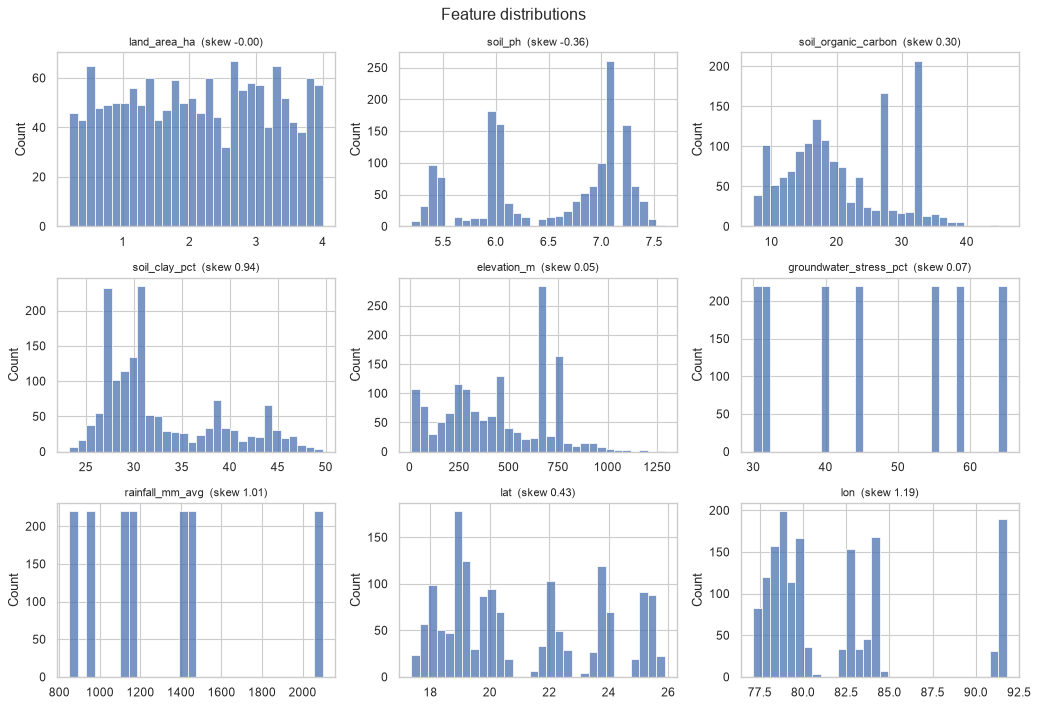

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, c in zip(axes.flat, NUMERIC):
    sns.histplot(df[c], bins=30, ax=ax, color="#4C72B0"); ax.set_title(f"{c}  (skew {df[c].skew():.2f})", fontsize=10); ax.set_xlabel("")
fig.suptitle("Feature distributions"); plt.tight_layout(); plt.show()

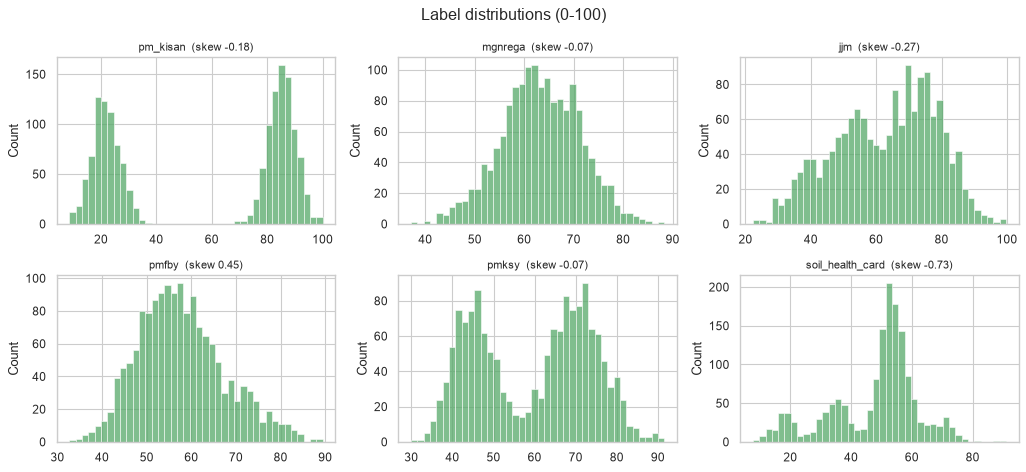

Labels clipped at the 0/100 bounds:
                         at 0  at 100
pm_kisan_score             0       1
mgnrega_score              0       0
jjm_score                  0       0
pmfby_score                0       0
pmksy_score                0       0
soil_health_card_score     0       0


In [15]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, t in zip(axes.flat, TARGETS):
    sns.histplot(df[t], bins=40, ax=ax, color="#55A868"); ax.set_title(f"{SHORT[t]}  (skew {df[t].skew():.2f})", fontsize=10); ax.set_xlabel("")
fig.suptitle("Label distributions (0-100)"); plt.tight_layout(); plt.show()
clip = pd.DataFrame({"at 0": (df[TARGETS] == 0).sum(), "at 100": (df[TARGETS] == 100).sum()})
print("Labels clipped at the 0/100 bounds:\n", clip.to_string())

**Reading it:**
- `land_area_ha` is flat because it was drawn uniformly at random.
- `soil_organic_carbon` is right-skewed.
- `groundwater_stress_pct` and `rainfall_mm_avg` show 7 spikes, one per district.
- `pm_kisan` is two humps (IFR vs non-IFR).
- `jjm`, `pmksy` and `pmfby` are lumpy because they are mostly district lookups.
- `mgnrega` is the only smooth, bell-shaped label.

## 3. Bivariate analysis: feature vs label

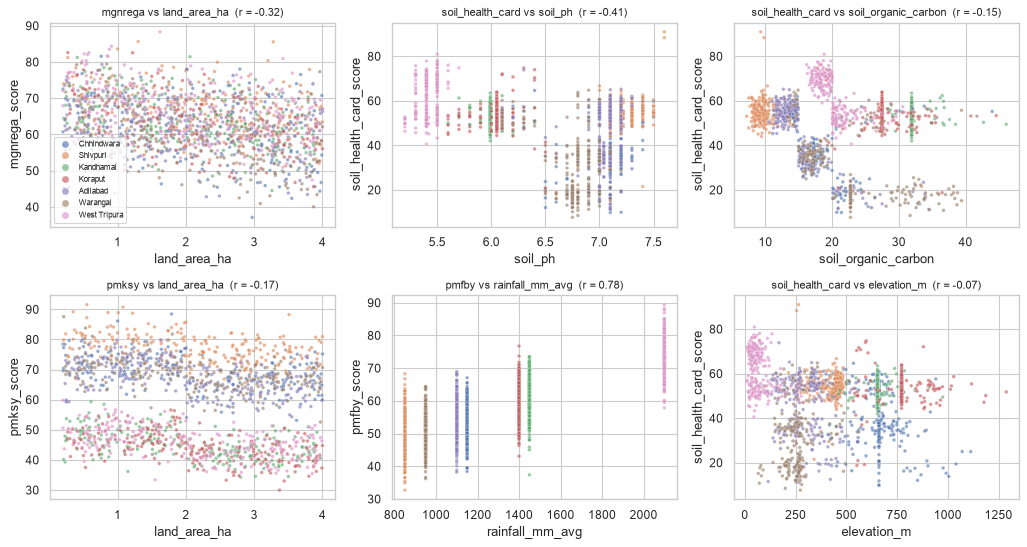

In [16]:
pairs = [("land_area_ha", "mgnrega_score"), ("soil_ph", "soil_health_card_score"),
         ("soil_organic_carbon", "soil_health_card_score"), ("land_area_ha", "pmksy_score"),
         ("rainfall_mm_avg", "pmfby_score"), ("elevation_m", "soil_health_card_score")]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (x, y) in zip(axes.flat, pairs):
    sns.scatterplot(data=df, x=x, y=y, hue="district", s=10, alpha=0.6, ax=ax, legend=(ax is axes.flat[0]))
    ax.set_title(f"{y.replace('_score','')} vs {x}  (r = {df[x].corr(df[y]):.2f})", fontsize=10)
axes.flat[0].legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()

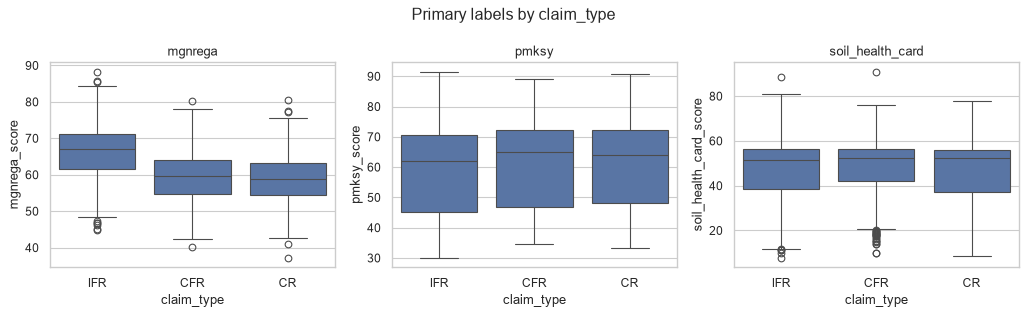

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, t in zip(axes, PRIMARY):
    sns.boxplot(data=df, x="claim_type", y=t, order=["IFR", "CFR", "CR"], ax=ax); ax.set_title(SHORT[t])
fig.suptitle("Primary labels by claim_type"); plt.tight_layout(); plt.show()

`soil_health_card` vs `soil_ph` shows the **step shape** of the rule: flat inside a band, then a jump at the cutoff. Elevation looks related only because elevation differs between districts (Finding 5).

## 4. Groups and geography

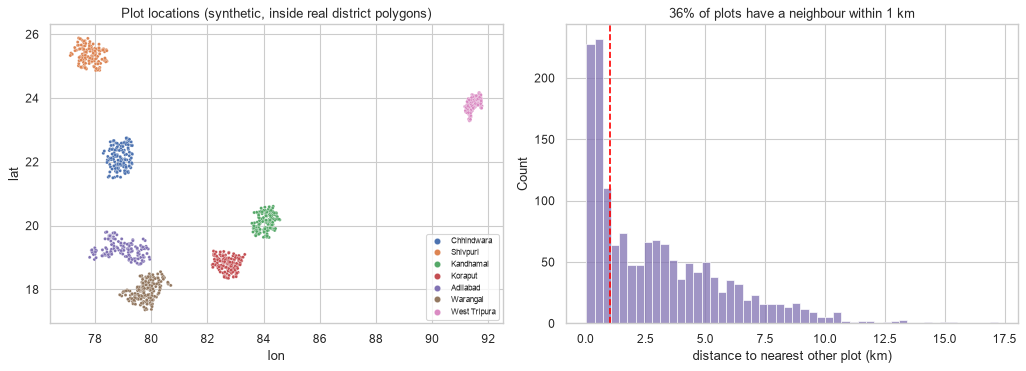

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=df, x="lon", y="lat", hue="district", s=8, ax=axes[0]); axes[0].set_title("Plot locations (synthetic, inside real district polygons)")
axes[0].legend(fontsize=7, markerscale=2)
sns.histplot(nn_km, bins=50, ax=axes[1], color="#8172B2"); axes[1].axvline(1, color="red", ls="--")
axes[1].set_xlabel("distance to nearest other plot (km)"); axes[1].set_title(f"{(nn_km < 1).mean():.0%} of plots have a neighbour within 1 km")
plt.tight_layout(); plt.show()

About 40% of each district's plots were sampled near real village points (`village_share=0.4` in `sample_geography.py`), so plots cluster. Clustering is the classic reason random splits leak. Here the measured leak is tiny (F7), because each plot's label noise is drawn independently, so a neighbour shares features but not noise. The split is still grouped by `spatial_block`: it costs nothing and stays correct if real (spatially correlated) labels ever replace the synthetic ones.

## 5. Imputation caveat (details)

In [19]:
imp_tab = df.groupby("district")[IMPUTED_FLAGS].mean().loc[DISTRICT_ORDER].mul(100).round(0)
imp_tab["soil_ph distinct values"] = df.groupby("district").soil_ph.nunique()
imp_tab

,soil_ph_imputed,soil_organic_carbon_imputed,soil_clay_pct_imputed,elevation_m_imputed,soil_ph distinct values
district,,,,,
Adilabad,12.0,13.0,13.0,0.0,13
Chhindwara,17.0,17.0,19.0,28.0,14
Kandhamal,83.0,83.0,83.0,82.0,11
Koraput,65.0,65.0,65.0,65.0,13
Shivpuri,5.0,6.0,6.0,0.0,8
Warangal,18.0,18.0,17.0,0.0,15
West Tripura,1.0,2.0,2.0,0.0,7


In Kandhamal and Koraput most rows carry a single repeated soil value, and their labels were computed **from** those imputed values. Two consequences for Stage 2:
1. Report error separately for imputed and real rows.
2. Re-run the main model **without** imputed rows to see whether the conclusions hold.

## 6. Outliers and cleaning

In [20]:
z = (df[NUMERIC] - df[NUMERIC].mean()) / df[NUMERIC].std()
q1, q3 = df[NUMERIC].quantile(0.25), df[NUMERIC].quantile(0.75)
iqr_out = ((df[NUMERIC] < q1 - 1.5 * (q3 - q1)) | (df[NUMERIC] > q3 + 1.5 * (q3 - q1))).sum()
pd.DataFrame({"|z| > 3": (z.abs() > 3).sum(), "IQR rule": iqr_out})

,|z| > 3,IQR rule
land_area_ha,0,0
soil_ph,0,0
soil_organic_carbon,1,0
soil_clay_pct,0,0
elevation_m,1,1
groundwater_stress_pct,0,0
rainfall_mm_avg,0,0
lat,0,0
lon,0,0


**Decision: remove nothing.** The flagged points are real SoilGrids readings or elevations from hilly districts, all within physical limits. Removing them would shrink the range the model learns from, and the rules depend on exactly those values. The labels are already clipped to 0–100 by the generator.

## 7. Smoothing
Labels have Gaussian noise (SD 4–6), so a trend can hide in the scatter. A **rolling mean** (average of the nearest *k* points along the x-axis) smooths the noise and shows the underlying rule.

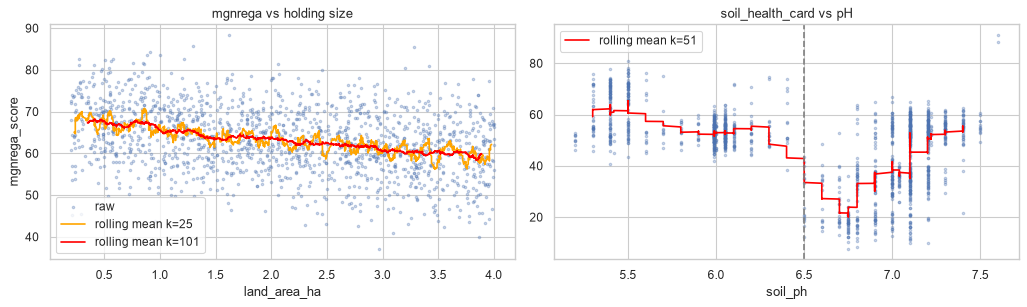

In [21]:
s = df.sort_values("land_area_ha")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(s.land_area_ha, s.mgnrega_score, s=5, alpha=0.3, label="raw")
for k, c in [(25, "orange"), (101, "red")]:
    axes[0].plot(s.land_area_ha, s.mgnrega_score.rolling(k, center=True).mean(), color=c, label=f"rolling mean k={k}")
axes[0].set_xlabel("land_area_ha"); axes[0].set_ylabel("mgnrega_score"); axes[0].legend(); axes[0].set_title("mgnrega vs holding size")
s2 = df.sort_values("soil_ph")
axes[1].scatter(s2.soil_ph, s2.soil_health_card_score, s=5, alpha=0.3)
axes[1].plot(s2.soil_ph, s2.soil_health_card_score.rolling(51, center=True).mean(), color="red", label="rolling mean k=51")
axes[1].axvline(6.5, ls="--", color="grey"); axes[1].set_xlabel("soil_ph"); axes[1].legend(); axes[1].set_title("soil_health_card vs pH")
plt.tight_layout(); plt.show()

The smoothed mgnrega line falls as holding size grows (the rule favours small holdings). The pH curve steps down at 6.5. Smoothing here is for **seeing** trends only; models train on the raw labels.

## 8. Encoding choices
- `claim_type` has 3 unordered categories, so it is **one-hot encoded**. Label-encoding it as 0/1/2 would invent an order (IFR < CFR < CR) that doesn't exist. Linear models drop one column (`drop_first`) to avoid perfect collinearity; trees can keep all three.
- `district` is **not a feature**. `groundwater_stress_pct` and `rainfall_mm_avg` already encode it exactly (7 values ↔ 7 districts), so adding it again adds no information. It is kept as a reporting and grouping key.
- `ph_band` (engineered below) is ordinal (acidic < neutral < alkaline), so integer coding is legitimate there.

In [22]:
pd.get_dummies(df[["claim_type"]], prefix="ct").head()

,ct_CFR,ct_CR,ct_IFR
0,False,False,True
1,False,False,True
2,False,True,False
3,False,False,True
4,False,False,True


## 9. Scaling
Features live on very different scales: pH ≈ 5–8, elevation ≈ 0–1,300 m. Distance- and gradient-based models (KNN, SVR/SVM, linear with regularisation, MLP) would let elevation dominate. Trees are unaffected.

In [23]:
sample = df[["soil_ph", "elevation_m", "land_area_ha"]]
scaled = pd.concat({"raw": sample.describe().loc[["mean", "std", "min", "max"]],
                    "standard": pd.DataFrame(StandardScaler().fit_transform(sample), columns=sample.columns).describe().loc[["mean", "std", "min", "max"]],
                    "min-max": pd.DataFrame(MinMaxScaler().fit_transform(sample), columns=sample.columns).describe().loc[["mean", "std", "min", "max"]]})
scaled.round(2)

soil_ph  elevation_m  land_area_ha
raw      mean     6.51       445.06          2.11
         std      0.66       254.79          1.10
         min      5.20         9.00          0.20
         max      7.60      1288.00          4.00
standard mean    -0.00         0.00          0.00
         std      1.00         1.00          1.00
         min     -1.98        -1.71         -1.74
         max      1.65         3.31          1.72
min-max  mean     0.55         0.34          0.50
         std      0.28         0.20          0.29
         min      0.00         0.00          0.00
         max      1.00         1.00          1.00

**Choice: StandardScaler**, fitted on the training split only and placed inside the sklearn `Pipeline`, so test data never leaks into the mean and standard deviation. Min-max is sensitive to extremes and the elevation tail is long.

## 10. Transforms

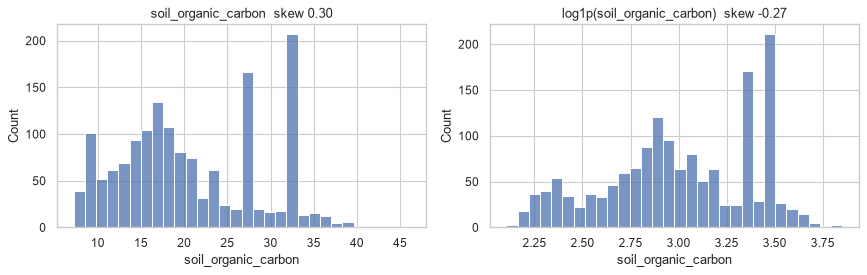

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (name, ser) in zip(axes, [("soil_organic_carbon", df.soil_organic_carbon), ("log1p(soil_organic_carbon)", np.log1p(df.soil_organic_carbon))]):
    sns.histplot(ser, bins=30, ax=ax); ax.set_title(f"{name}  skew {ser.skew():.2f}")
plt.tight_layout(); plt.show()

A log transform reduces the organic-carbon skew. However, the rule cuts organic carbon at fixed **percent** thresholds, so keeping (or converting to) the original scale keeps those thresholds readable. **Decision:** no log transform. Use `oc_pct` = g/kg ÷ 10, which is a pure unit change and keeps the rule's cutoffs (1.5% / 2.0%) directly interpretable.

## 11. Engineered features
- `oc_pct`: organic carbon in **percent** (the rule's unit).
- `ph_band`: 0 acidic (<6.5) / 1 neutral / 2 alkaline (>7.5), the Soil Health Card band.
- `small_holding`: land ≤ 2 ha (the PMKSY rule threshold).
- `is_ifr`: individual claim (drives pm_kisan, mgnrega, pmksy).

These mirror the rule's own thresholds, so for this synthetic data they *should* help simpler models. This is a known shortcut, not a discovery.

               mean   min   max
oc_pct         2.07  0.72  4.61
ph_band        0.55  0.00  2.00
small_holding  0.47  0.00  1.00
is_ifr         0.55  0.00  1.00


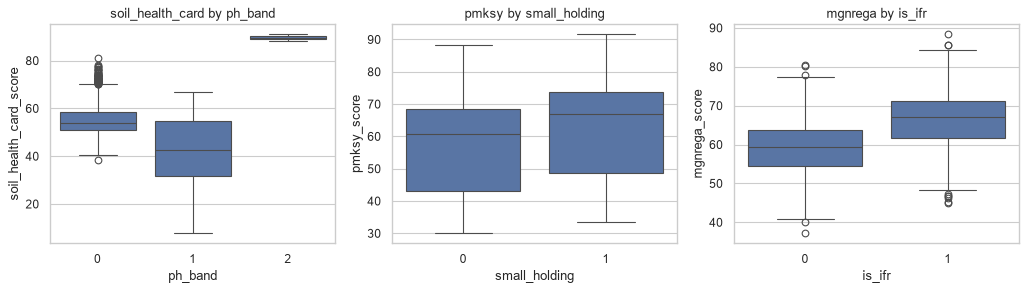

ph_band counts: {0: 691, 1: 847, 2: 2} (alkaline band is nearly empty)


In [25]:
df["oc_pct"] = df.soil_organic_carbon / 10
df["ph_band"] = np.select([df.soil_ph < sr.PH_LOW, df.soil_ph > sr.PH_HIGH], [0, 2], 1)
df["small_holding"] = (df.land_area_ha <= 2.0).astype(int)
eng = ["oc_pct", "ph_band", "small_holding", "is_ifr"]
print(df[eng].describe().round(2).T[["mean", "min", "max"]])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
sns.boxplot(data=df, x="ph_band", y="soil_health_card_score", ax=axes[0]); axes[0].set_title("soil_health_card by ph_band")
sns.boxplot(data=df, x="small_holding", y="pmksy_score", ax=axes[1]); axes[1].set_title("pmksy by small_holding")
sns.boxplot(data=df, x="is_ifr", y="mgnrega_score", ax=axes[2]); axes[2].set_title("mgnrega by is_ifr")
plt.tight_layout(); plt.show()
print("ph_band counts:", df.ph_band.value_counts().sort_index().to_dict(), "(alkaline band is nearly empty)")

## 12. PCA preview (features)
PCA rotates the standardized features into uncorrelated directions ordered by variance. It previews how many dimensions the feature space really has (dimensionality reduction comes up again in Unit 5).

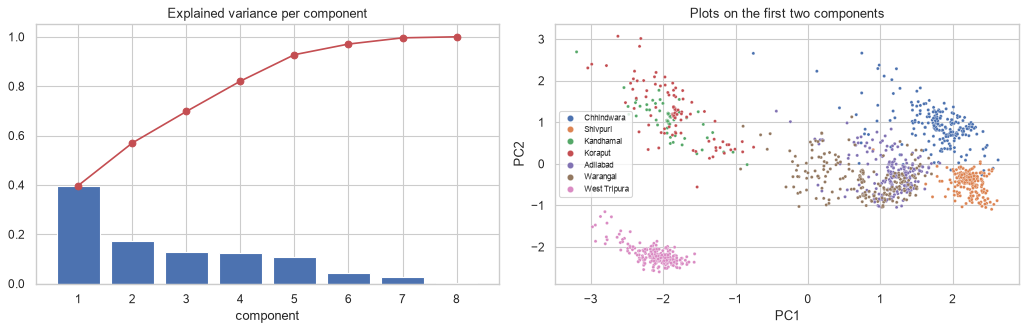

,PC1,PC2
land_area_ha,0.01,-0.03
soil_ph,0.53,0.19
oc_pct,-0.43,0.39
soil_clay_pct,0.28,0.16
elevation_m,-0.04,0.80
groundwater_stress_pct,0.50,-0.18
rainfall_mm_avg,-0.45,-0.33
is_ifr,-0.01,-0.09


In [26]:
pca_feats = ["land_area_ha", "soil_ph", "oc_pct", "soil_clay_pct", "elevation_m", "groundwater_stress_pct", "rainfall_mm_avg", "is_ifr"]
Z = StandardScaler().fit_transform(df[pca_feats])
pca = PCA().fit(Z); P = pca.transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].bar(range(1, len(pca_feats) + 1), pca.explained_variance_ratio_); axes[0].plot(range(1, len(pca_feats) + 1), np.cumsum(pca.explained_variance_ratio_), "ro-")
axes[0].set_title("Explained variance per component"); axes[0].set_xlabel("component")
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df.district, s=8, ax=axes[1]); axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("Plots on the first two components"); axes[1].legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()
pd.DataFrame(pca.components_[:2].T, index=pca_feats, columns=["PC1", "PC2"]).round(2)

PC1 mixes soil pH, groundwater, rainfall and organic carbon. All four are (near-)district attributes here (F5, F10). PC2 is mostly elevation. On the first two components the plots form one cloud per district, so the main axis of variation in the features is "which district", and that is exactly what the district-lookup labels follow. `land_area_ha` and `is_ifr` barely load on PC1/PC2: they vary *within* districts and sit in later components.

---
# Decisions log (Stage 2 follows these)

| Decision | Choice | Why |
|---|---|---|
| **Primary targets** | `mgnrega_score`, `pmksy_score`, `soil_health_card_score` | Only labels with meaningful within-district signal (F1). mgnrega is the only continuous multi-factor label |
| **Side experiments** | `jjm_score`, `pmfby_score`, `pm_kisan_score` | jjm/pmfby are district lookups (F1, F10); pm_kisan is a claim_type lookup (F9) |
| **Features** | `land_area_ha`, `claim_type` (one-hot), `soil_ph`, `soil_organic_carbon` (as `oc_pct`), `groundwater_stress_pct`, `rainfall_mm_avg`; engineered `ph_band`, `small_holding` | Everything the rules read (F2), in the rule's own units |
| **Excluded features** | `lat`, `lon`, `elevation_m`, `soil_clay_pct` | No rule uses them (F5), and lat/lon steal importance from the real inputs (F2), which would make DSS explanations misleading. Kept in one ablation run in Stage 2 to show the effect |
| **Scope** | Only the 7 training districts | Leave-one-district-out collapses for the district-driven labels (F7) |
| **Not features** | `district`, `state`, `plot_id`, `spatial_block`, `*_imputed` | district is already encoded by the climate columns; the rest are IDs, grouping keys or stratifiers |
| **Encoding** | `claim_type` one-hot (`drop_first` for linear models); `ph_band` ordinal 0/1/2 | No false ordering for claim_type (§8) |
| **Scaling** | `StandardScaler` inside the `Pipeline`, fit on train only | Needed for linear/SVR/KNN/SVM/MLP; harmless for trees (§9) |
| **Transforms** | none beyond `oc_pct` = g/kg ÷ 10 | Keeps rule thresholds interpretable (§10) |
| **Outliers** | keep all rows | Physically valid, rule-relevant (§6) |
| **Imputed rows** | keep for training; always report metrics split by imputed vs real, plus one run without imputed rows | F4 |
| **Split** | `GroupShuffleSplit(test_size=0.2, random_state=42)` on `spatial_block` for a single held-out test set; `GroupKFold(5)` on `spatial_block` inside train for tuning | Group split is the honest default; the leak gap is small but non-zero (F7) |
| **Robustness** | leave-one-district-out; expected to fail on jjm/pmfby/pmksy | F7, F10 |
| **Benchmarks** | training mean, per-district mean, per-claim_type mean, and the R² ceiling | Above the ceiling = leakage (F1) |
| **Classification labels** | `pmksy` terciles with cut points computed on the **training split only**; sanity check `pm_kisan_score > 50` vs `claim_type == "IFR"` | F9 |
| **Seed** | 42 everywhere | Reproducibility |

**Reminder for every result that follows:** a good score means the model recovered the rules in `scheme_rules.py`. It says nothing about real-world eligibility, because no real allocation or outcome data exists yet.